In [1]:
from pathlib import Path
import pandas as pd

raw = Path("../data/raw")
tables = {p.stem: pd.read_csv(p, low_memory=False) for p in sorted(raw.glob("*.csv"))}
for name, df in tables.items():
    print(name, df.shape)

customers (200, 8)
delivery_events (170820, 11)
driver_monthly_metrics (4464, 9)
drivers (150, 12)
facilities (50, 9)
fuel_purchases (196442, 11)
loads (85410, 12)
maintenance_records (2920, 12)
routes (58, 9)
safety_incidents (170, 15)
trailers (180, 9)
trips (85410, 12)
truck_utilization_metrics (3312, 10)
trucks (120, 11)


In [2]:
loads = tables["loads"]
loads.head()

,load_id,customer_id,route_id,load_date,load_type,weight_lbs,pieces,revenue,fuel_surcharge,accessorial_charges,load_status,booking_type
0,LOAD00000001,CUST00183,RTE00019,2022-01-01,Dry Van,19178,13,3045.23,406.72,100,Completed,Spot
1,LOAD00000002,CUST00076,RTE00058,2022-01-01,Dry Van,27761,22,1224.48,98.61,0,Completed,Dedicated
2,LOAD00000003,CUST00027,RTE00048,2022-01-01,Refrigerated,35594,16,7171.12,792.88,0,Completed,Spot
3,LOAD00000004,CUST00088,RTE00013,2022-01-01,Refrigerated,33274,10,1308.20,141.33,50,Completed,Spot
4,LOAD00000005,CUST00185,RTE00020,2022-01-01,Dry Van,40257,10,3317.18,738.48,0,Completed,Spot


In [3]:
loads.info()

<class 'pandas.DataFrame'>
RangeIndex: 85410 entries, 0 to 85409
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   load_id              85410 non-null  str    
 1   customer_id          85410 non-null  str    
 2   route_id             85410 non-null  str    
 3   load_date            85410 non-null  str    
 4   load_type            85410 non-null  str    
 5   weight_lbs           85410 non-null  int64  
 6   pieces               85410 non-null  int64  
 7   revenue              85410 non-null  float64
 8   fuel_surcharge       85410 non-null  float64
 9   accessorial_charges  85410 non-null  int64  
 10  load_status          85410 non-null  str    
 11  booking_type         85410 non-null  str    
dtypes: float64(2), int64(3), str(7)
memory usage: 7.8 MB


In [4]:
loads.describe()

,weight_lbs,pieces,revenue,fuel_surcharge,accessorial_charges
count,85410.000000,85410.000000,85410.000000,85410.000000,85410.000000
mean,27477.495305,14.470530,3073.712683,350.972119,71.643836
std,10095.421857,8.070077,1883.127436,218.034684,70.018823
min,10000.000000,1.000000,125.930000,13.800000,0.000000
25%,18724.000000,7.000000,1443.215000,161.530000,0.000000
50%,27482.000000,14.000000,2827.985000,314.640000,50.000000
75%,36190.000000,21.000000,4323.157500,499.180000,100.000000
max,45000.000000,28.000000,8125.220000,891.820000,200.000000


In [5]:
loads["load_date"] = pd.to_datetime(loads["load_date"])
print(loads["load_date"].dtype)

datetime64[us]


In [6]:
daily = loads.groupby("load_date").size().rename("loads")
print(daily.shape, daily.index.min().date(), daily.index.max().date())
print(daily.index.to_series().diff().dt.days.max()) # daily continuity check

(1096,) 2022-01-01 2024-12-31
1.0


In [7]:
daily.head()

load_date
2022-01-01    71
2022-01-02    70
2022-01-03    79
2022-01-04    70
2022-01-05    77
Name: loads, dtype: int64

In [8]:
test  = daily.iloc[-84:]
valid = daily.iloc[-168:-84]
train = daily.iloc[:-168]

for name, s in [("train", train), ("valid", valid), ("test", test)]:
    print(name, s.index.min().date(), s.index.max().date(), len(s))

train 2022-01-01 2024-07-16 928
valid 2024-07-17 2024-10-08 84
test 2024-10-09 2024-12-31 84


In [9]:
# baseline for 14-day forecast option 1

from sklearn.metrics import mean_absolute_error

def scores(actual, pred):
    mae = mean_absolute_error(actual, pred)
    return round(mae, 2), f"{mae / actual.mean():.2%}" # returns MAE and WAPE

pred_1 = daily.shift(7).loc[valid.index] # same day last week
print(scores(valid, pred_1))

(10.21, '13.01%')


In [10]:
# baseline for 14-day forecast option 2

import numpy as np

pos = np.arange(len(valid)) % 14
lag = np.where(pos < 7, 7, 14)
pred_14 = pd.Series(
    [daily.loc[d - pd.Timedelta(days=int(k))] for d, k in zip(valid.index, lag)],
    index=valid.index,
)
print(scores(valid, pred_14))

(10.98, '13.98%')


In [11]:
# baseline for 14-day forecast option 3
pred_3 = pd.Series(train.mean(), index=valid.index)
print(scores(valid, pred_3))

(7.31, '9.31%')


In [12]:
# baseline for 14-day forecast option 4
p4 = []
for w in range(6):
    start = valid.index[w * 14]
    hist = daily.loc[:start - pd.Timedelta(days=1)].iloc[-28:]
    p4 += [hist.mean()] * 14
pred_4 = pd.Series(p4, index=valid.index)
print(scores(valid, pred_4))

(7.27, '9.27%')


In [13]:
# baseline for 14-day forecast option 5
prof = train.groupby(train.index.dayofweek).mean()
pred_5 = pd.Series(prof.loc[valid.index.dayofweek].values, index=valid.index)
print(scores(valid, pred_5))

(7.16, '9.12%')


C:\Users\Blessie\AppData\Local\Temp\ipykernel_19132\4172486535.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  prof = train.groupby(train.index.dayofweek).mean()
C:\Users\Blessie\AppData\Local\Temp\ipykernel_19132\4172486535.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  pred_5 = pd.Series(prof.loc[valid.index.dayofweek].values, index=valid.index)


In [14]:
# baseline for 14-day forecast comparison
results = {"1 one-step": pred_1, "2 lag 7/14": pred_14, "3 train mean": pred_3,
           "4 trailing 28d": pred_4, "5 weekday profile": pred_5}
pd.DataFrame({k: scores(valid, v) for k, v in results.items()}, index=["MAE", "WAPE"]).T

,MAE,WAPE
1 one-step,10.21,13.01%
2 lag 7/14,10.98,13.98%
3 train mean,7.31,9.31%
4 trailing 28d,7.27,9.27%
5 weekday profile,7.16,9.12%


In [15]:
# baseline for 14-day forecast per-window comparison
w = lambda p: [round((valid - p).abs().iloc[i*14:(i+1)*14].mean(), 1) for i in range(6)]
print(w(pred_14)); print(w(pred_3))

[np.float64(12.6), np.float64(7.5), np.float64(7.1), np.float64(14.6), np.float64(14.1), np.float64(9.8)]
[np.float64(7.5), np.float64(5.5), np.float64(7.1), np.float64(10.9), np.float64(5.2), np.float64(7.7)]


In [16]:
# dataset scope option 1: save daily series

daily.to_csv("../data/processed/daily_loads.csv")
print(pd.read_csv("../data/processed/daily_loads.csv", index_col=0, parse_dates=True).shape)

(1096, 1)


In [17]:
# dataset scope option 2: save split dates

import json

splits = {name: [str(s.index.min().date()), str(s.index.max().date())]
          for name, s in [("train", train), ("valid", valid), ("test", test)]}
with open("../data/processed/splits.json", "w") as f:
    json.dump(splits, f, indent=2)
print(splits)

{'train': ['2022-01-01', '2024-07-16'], 'valid': ['2024-07-17', '2024-10-08'], 'test': ['2024-10-09', '2024-12-31']}


In [18]:
# dataset scope option 3: coverage facts

print(len(loads), len(tables["delivery_events"]), daily.index.min().date(),
      daily.index.max().date(), len(daily), loads["route_id"].nunique())

85410 170820 2022-01-01 2024-12-31 1096 58


In [19]:
# route aggregation option 1: origin_state groups

routes = tables["routes"]
tr = loads[loads["load_date"] <= train.index.max()].merge(routes, on="route_id")
g = tr.groupby(["origin_state", "load_date"]).size().unstack(0, fill_value=0)
print(g.shape[1], g.mean().min().round(1), g.mean().max().round(1))
print(g.apply(lambda s: s.autocorr(7)).round(2).max())

17 1.4 9.4
0.03


In [20]:
# delivery events option 1: load and parse

events = tables["delivery_events"].copy()
for c in ["scheduled_datetime", "actual_datetime"]:
    events[c] = pd.to_datetime(events[c])
events = events.merge(loads[["load_id", "load_date"]], on="load_id")
ev_tr = events[events["load_date"] <= train.index.max()].copy()
print(len(events), len(ev_tr), events["event_type"].value_counts().to_dict())
print(ev_tr[["scheduled_datetime", "actual_datetime", "detention_minutes", "on_time_flag"]].isna().sum().sum())

170820 144618 {'Pickup': 85410, 'Delivery': 85410}
0


In [21]:
# delivery events option 2: delay and detention (train)

ev_tr["delay_min"] = (ev_tr["actual_datetime"] - ev_tr["scheduled_datetime"]).dt.total_seconds() / 60
print(ev_tr.groupby("event_type")[["delay_min", "detention_minutes"]].quantile([.05, .5, .95]).unstack().round(0))

           delay_min              detention_minutes              
                0.05  0.50   0.95              0.05   0.50   0.95
event_type                                                       
Delivery      -153.0  90.0  333.0               0.0  105.0  226.0
Pickup        -102.0  60.0  221.0               0.0   74.0  169.0


array([<Axes: title={'center': 'Delivery'}>,
       <Axes: title={'center': 'Pickup'}>], dtype=object)

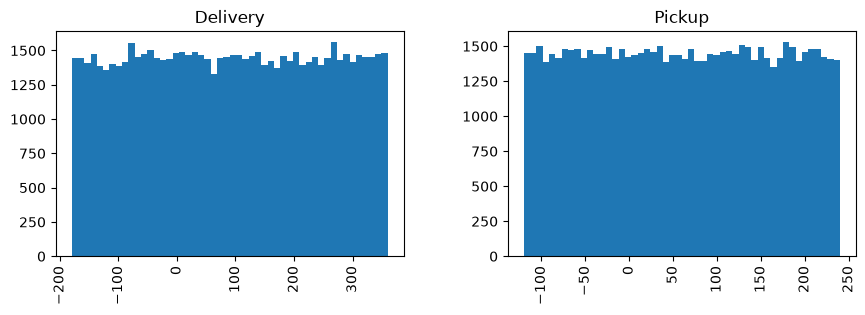

In [22]:
# delivery events option 2b: delay histogram

ev_tr["delay_min"].hist(by=ev_tr["event_type"], bins=50, figsize=(10, 3))

In [23]:
# delivery events option 3a: is flag False the same as "after schedule"?

for ev, g in ev_tr.groupby("event_type"):
    print(ev, round(((g["delay_min"] > 0) == ~g["on_time_flag"]).mean(), 3))

Delivery 0.667
Pickup 0.668


In [24]:
# delivery events option 3b: is the flag a +/-120 minute window?

for ev, g in ev_tr.groupby("event_type"):
    print(ev, round(((g["delay_min"].abs() <= 120) == g["on_time_flag"]).mean(), 3))

Delivery 1.0
Pickup 1.0


In [25]:
# delivery events option 3c: own late and early rates

for ev, g in ev_tr.groupby("event_type"):
    print(ev, round((g["delay_min"] > 120).mean(), 3), round((g["delay_min"] < -120).mean(), 3))

Delivery 0.444 0.109
Pickup 0.333 0.0


In [26]:
# delivery events option 4: delivery earlier than pickup

t = events.pivot(index="load_id", columns="event_type", values="actual_datetime")
bad = t["Delivery"] < t["Pickup"]
print(len(t), int(bad.sum()), round(bad.mean() * 100, 2))
print(((t["Pickup"] - t["Delivery"])[bad].dt.total_seconds() / 3600).describe().round(1))

85410 486 0.57
count    486.0
mean       0.7
std        0.4
min        0.0
25%        0.3
50%        0.7
75%        1.0
max        1.5
dtype: float64


In [27]:
# delivery events option 5: scheduled delivery before scheduled pickup

s = events.pivot(index="load_id", columns="event_type", values="scheduled_datetime")
print(int((s["Delivery"] < s["Pickup"]).sum()))

175


In [28]:
# delivery events option 6: which routes have order errors?
t = events.pivot(index="load_id", columns="event_type", values="actual_datetime")
bad_ids = t.index[t["Delivery"] < t["Pickup"]]
print(loads[loads["load_id"].isin(bad_ids)]["route_id"].value_counts().head(3))

route_id
RTE00015    261
RTE00010    206
RTE00033     19
Name: count, dtype: int64


In [29]:
# delivery events option 7: which routes have scheduled-order errors?
s = events.pivot(index="load_id", columns="event_type", values="scheduled_datetime")
bad_s = s.index[s["Delivery"] < s["Pickup"]]
print(loads[loads["load_id"].isin(bad_s)]["route_id"].value_counts())

route_id
RTE00010    89
RTE00015    86
Name: count, dtype: int64


In [30]:
# eda summary option 1: missing values, duplicates, foreign keys
miss = pd.concat({n: df.isna().sum()[lambda s: s > 0] for n, df in tables.items()})
print(miss)
print({n: int(df.duplicated().sum()) for n, df in tables.items() if df.duplicated().sum()})
print(loads["customer_id"].isin(tables["customers"]["customer_id"]).all(),
      tables["delivery_events"]["load_id"].isin(loads["load_id"]).all())

drivers           termination_date     124
fuel_purchases    truck_id            3880
                  driver_id           3988
safety_incidents  truck_id               1
                  driver_id              1
trips             driver_id           1714
                  truck_id            1672
                  trailer_id          1680
dtype: int64
{}
True True


In [31]:
# calendar features option 1: weekday, month, week, day-of-year
cal = pd.DataFrame(index=daily.index)
cal["dow"] = cal.index.day_of_week
cal["month"] = cal.index.month
cal["week"] = cal.index.isocalendar().week.astype(int)
cal["doy"] = cal.index.day_of_year
print(cal.head(3)); print(cal.shape)

            dow  month  week  doy
load_date                        
2022-01-01    5      1    52    1
2022-01-02    6      1    52    2
2022-01-03    0      1     1    3
(1096, 4)


In [32]:
# calendar features option 2: month-end and US federal holiday flags
from pandas.tseries.holiday import USFederalHolidayCalendar

hol = USFederalHolidayCalendar().holidays(start=daily.index.min(), end=daily.index.max())
cal["is_month_end"] = cal.index.is_month_end.astype(int)
cal["is_holiday"] = cal.index.isin(hol).astype(int)
print(cal["is_month_end"].sum(), cal["is_holiday"].sum())

36 32


In [33]:
# calendar features option 3: cyclical encoding
for col, period in [("dow", 7), ("month", 12), ("doy", 365.25)]:
    cal[col + "_sin"] = np.sin(2 * np.pi * cal[col] / period)
    cal[col + "_cos"] = np.cos(2 * np.pi * cal[col] / period)
print(cal.filter(like="dow_").head(8).round(2))

            dow_sin  dow_cos
load_date                   
2022-01-01    -0.97    -0.22
2022-01-02    -0.78     0.62
2022-01-03     0.00     1.00
2022-01-04     0.78     0.62
2022-01-05     0.97    -0.22
2022-01-06     0.43    -0.90
2022-01-07    -0.43    -0.90
2022-01-08    -0.97    -0.22


In [34]:
# calendar features option 4: one function, then a leakage check
def make_calendar(idx):
    c = pd.DataFrame(index=idx)
    c["dow"] = idx.day_of_week
    c["month"] = idx.month
    c["week"] = idx.isocalendar().week.astype(int).to_numpy()
    c["doy"] = idx.day_of_year
    hol = USFederalHolidayCalendar().holidays(start=idx.min(), end=idx.max())
    c["is_month_end"] = idx.is_month_end.astype(int)
    c["is_holiday"] = idx.isin(hol).astype(int)
    for col, period in [("dow", 7), ("month", 12), ("doy", 365.25)]:
        c[col + "_sin"] = np.sin(2 * np.pi * c[col] / period)
        c[col + "_cos"] = np.cos(2 * np.pi * c[col] / period)
    return c

same = make_calendar(train.index).equals(make_calendar(daily.index).loc[train.index])
print(same, make_calendar(train.index).shape)
print(make_calendar(pd.date_range("2025-01-01", periods=14)).shape)

True (928, 12)
(14, 12)


In [35]:
# calendar features option 5: signal check on train only
feat = make_calendar(daily.index)
print(feat.loc[train.index].corrwith(train).abs().sort_values().tail(3).round(3))

is_month_end    0.040
dow_sin         0.074
dow             0.091
dtype: float64


In [36]:
# lag features option 1: which lags are usable for the whole horizon?
last_known = pd.Timestamp("2024-07-16")
horizon_days = pd.date_range(last_known + pd.Timedelta(days=1), periods=14)
for k in (7, 14):
    ok = (horizon_days - pd.Timedelta(days=k) <= last_known).all()
    print(f"lag {k} usable for all 14 days:", ok)

lag 7 usable for all 14 days: False
lag 14 usable for all 14 days: True


In [37]:
# lag features option 2: lag_14, lag_21, lag_28
lags = pd.DataFrame({f"lag_{k}": daily.shift(k) for k in (14, 21, 28)})
print(lags.iloc[28:31]); print(lags.isna().sum().to_dict())

            lag_14  lag_21  lag_28
load_date                         
2022-01-29   101.0    80.0    71.0
2022-01-30    72.0    81.0    70.0
2022-01-31    86.0    90.0    79.0
{'lag_14': 14, 'lag_21': 21, 'lag_28': 28}


In [38]:
# lag features option 3: rolling mean and std on the shifted series
base = daily.shift(14)
roll = pd.DataFrame({
    "roll_mean_7": base.rolling(7).mean(),
    "roll_mean_28": base.rolling(28).mean(),
    "roll_std_28": base.rolling(28).std(),
})
print(roll.iloc[41:43].round(1)); print(roll.isna().sum().to_dict())

            roll_mean_7  roll_mean_28  roll_std_28
load_date                                         
2022-02-11         78.3          79.3          7.3
2022-02-12         78.7          79.9          7.3
{'roll_mean_7': 20, 'roll_mean_28': 41, 'roll_std_28': 41}


In [39]:
# lag features option 4: one function, then a poison test
def make_lags(s):
    base = s.shift(14)
    f = pd.DataFrame({f"lag_{k}": s.shift(k) for k in (14, 21, 28)})
    f["roll_mean_7"] = base.rolling(7).mean()
    f["roll_mean_28"] = base.rolling(28).mean()
    f["roll_std_28"] = base.rolling(28).std()
    return f

d = pd.Timestamp("2024-03-15")
poisoned = daily.copy()
poisoned.loc[poisoned.index > d - pd.Timedelta(days=14)] = 9999
print("identical (no leak):", make_lags(daily).loc[d].equals(make_lags(poisoned).loc[d]))

identical (no leak): True


In [40]:
# lag features option 5: the same test on a leaky feature
leaky = daily.shift(1).rolling(7).mean()
leaky_poisoned = poisoned.shift(1).rolling(7).mean()
print("leaky identical:", leaky.loc[d] == leaky_poisoned.loc[d], round(leaky.loc[d], 1), round(leaky_poisoned.loc[d], 1))

leaky identical: False 81.9 9999.0


In [41]:
# lag features option 6: signal check on train only
feat = make_lags(daily)
print(feat.loc[train.index].dropna().shape)
print(feat.loc[train.index].corrwith(train).abs().sort_values().tail(3).round(3))

(887, 6)
lag_21         0.017
roll_std_28    0.025
roll_mean_7    0.044
dtype: float64


In [42]:
# eda summary option 1: missing values, duplicates, foreign keys
miss = pd.concat({n: df.isna().sum()[lambda s: s > 0] for n, df in tables.items()})
print(miss)
print({n: int(df.duplicated().sum()) for n, df in tables.items() if df.duplicated().sum()})
print(loads["customer_id"].isin(tables["customers"]["customer_id"]).all(),
      tables["delivery_events"]["load_id"].isin(loads["load_id"]).all())

drivers           termination_date     124
fuel_purchases    truck_id            3880
                  driver_id           3988
safety_incidents  truck_id               1
                  driver_id              1
trips             driver_id           1714
                  truck_id            1672
                  trailer_id          1680
dtype: int64
{}
True True


In [43]:
# route region features option 1: build two candidates
rt = loads.merge(tables["routes"][["route_id", "origin_state", "typical_distance_miles"]], on="route_id")
top_state = rt[rt["load_date"] <= train.index.max()]["origin_state"].value_counts().idxmax()

def make_route_features(rt, top_state):
    day = rt.assign(is_top=rt["origin_state"] == top_state).groupby("load_date")
    return pd.DataFrame({
        "top_state_share_28": day["is_top"].mean().shift(14).rolling(28).mean(),
        "avg_distance_28": day["typical_distance_miles"].mean().shift(14).rolling(28).mean(),
    })

cand = make_route_features(rt, top_state)
print(top_state, cand.shape, cand.isna().sum().to_dict())
print(cand.loc["2024-03-15"].round(3).to_dict())

TX (1096, 2) {'top_state_share_28': 41, 'avg_distance_28': 41}
{'top_state_share_28': 0.123, 'avg_distance_28': 1400.976}


In [44]:
# route region features option 2: poison test
d = pd.Timestamp("2024-03-15")
bad = rt.copy()
mask = bad["load_date"] > d - pd.Timedelta(days=14)
bad.loc[mask, "typical_distance_miles"] = 9999
bad.loc[mask, "origin_state"] = top_state
print("identical (no leak):", make_route_features(rt, top_state).loc[d].equals(make_route_features(bad, top_state).loc[d]))

identical (no leak): True


In [45]:
# route region features option 3: signal check on train
print(cand.loc[train.index].corrwith(train).abs().round(3).to_dict())
print(round(2 / np.sqrt(len(cand.loc[train.index].dropna())), 3))

{'top_state_share_28': 0.06, 'avg_distance_28': 0.001}
0.067


In [46]:
# feature leakage audit option 1: poison test on every feature, five dates
import sys
sys.path.append("..")
from src.features import build_features

clean = build_features(daily)
for d in pd.to_datetime(["2022-06-15", "2023-01-10", "2023-09-05", "2024-03-15", "2024-07-10"]):
    poisoned = daily.copy()
    poisoned.loc[poisoned.index > d - pd.Timedelta(days=14)] = 9999
    print(d.date(), "identical (no leak):", build_features(poisoned).loc[d].equals(clean.loc[d]))

2022-06-15 identical (no leak): True
2023-01-10 identical (no leak): True
2023-09-05 identical (no leak): True
2024-03-15 identical (no leak): True
2024-07-10 identical (no leak): True


In [47]:
# feature leakage audit option 2: a known-bad feature must fail
def leaky(s):
    return pd.DataFrame({"roll_mean_7_leaky": s.shift(1).rolling(7).mean()})

d = pd.Timestamp("2024-03-15")
poisoned = daily.copy()
poisoned.loc[poisoned.index > d - pd.Timedelta(days=14)] = 9999
print("leaky control identical:", leaky(poisoned).loc[d].equals(leaky(daily).loc[d]))

leaky control identical: False


In [48]:
# pipeline check option 1: do notebook features match the pipeline file?
saved = pd.read_csv("../data/processed/features.csv", index_col=0, parse_dates=True)
mine = pd.concat([make_calendar(daily.index), make_lags(daily)], axis=1)
print(np.allclose(saved[mine.columns].to_numpy(dtype=float), mine.to_numpy(dtype=float), equal_nan=True))

True


In [49]:
# pipeline checks option 3: bad-input test
import importlib
import src.data
importlib.reload(src.data)
from src.data import load_loads, validate_loads, validate_daily, build_daily

loads_raw = load_loads()
daily_ok = build_daily(loads_raw)

def expect_error(fn, arg, label):
    try:
        fn(arg)
        print(label, "-> NO ERROR (bad)")
    except ValueError as e:
        print(label, "-> raised:", e)

null_key = loads_raw.copy()
null_key.loc[0, "route_id"] = None
expect_error(validate_loads, loads_raw.drop(columns=["route_id"]), "missing column")
expect_error(validate_loads, loads_raw.assign(load_date=loads_raw["load_date"].astype(str)), "text dates")
expect_error(validate_loads, null_key, "null key")
expect_error(validate_loads, pd.concat([loads_raw, loads_raw.head(1)]), "duplicate id")
expect_error(validate_daily, daily_ok.drop(pd.Timestamp("2023-05-10")), "missing day")
expect_error(validate_daily, daily_ok.iloc[::-1], "reversed order")
print("clean passes:", validate_loads(loads_raw) is loads_raw, len(validate_daily(daily_ok)))

missing column -> raised: loads is missing columns: ['route_id']
text dates -> raised: load_date is not a date column (unparseable values?)
null key -> raised: nulls in key columns: {'route_id': 1}
duplicate id -> raised: loads has duplicate load_id values
missing day -> raised: daily series has 1 missing days
reversed order -> raised: daily dates are not unique and in increasing order
clean passes: True 1096


In [50]:
# seeds option 1: same seed, same numbers
from src.config import SEED, set_seeds

set_seeds()
a = np.random.rand(3)
set_seeds()
b = np.random.rand(3)
print(np.array_equal(a, b), np.round(a, 3))

True [0.375 0.951 0.732]


In [51]:
# anomaly alert measure option 1: precision and recall on a toy example
windows = [("volume", "2024-08-12", "2024-08-16")]
alerts = [("volume", "2024-08-13"), ("volume", "2024-08-20")]

def alert_scores(alerts, windows):
    alerts = [(s, pd.Timestamp(d)) for s, d in alerts]
    windows = [(s, pd.Timestamp(a), pd.Timestamp(b)) for s, a, b in windows]
    good = [any(s == ws and start <= d <= end for ws, start, end in windows) for s, d in alerts]
    found = [any(s == ws and start <= d <= end for s, d in alerts) for ws, start, end in windows]
    return sum(good) / max(len(alerts), 1), sum(found) / max(len(windows), 1)

print(alert_scores(alerts, windows))
print(alert_scores([], windows))

(0.5, 1.0)
(0.0, 0.0)


In [52]:
# better than baseline option 1: the bar and the noise
w = lambda p: [round((valid - p).abs().iloc[i*14:(i+1)*14].mean(), 1) for i in range(6)]
print(scores(valid, pred_5), w(pred_5))
diff = np.array(w(pred_3)) - np.array(w(pred_5))
print(diff.round(2).tolist(), round(diff.mean(), 2), round(diff.std(ddof=1) / np.sqrt(6), 2))
print(round(0.8 * valid.std(), 1))

(7.16, '9.12%') [np.float64(7.3), np.float64(5.2), np.float64(6.8), np.float64(10.9), np.float64(5.1), np.float64(7.7)]
[0.2, 0.3, 0.3, 0.0, 0.1, 0.0] 0.15 0.06
7.1


In [53]:
# reusable metrics option 1: same numbers as before
from src.metrics import scores
print(scores(valid, pred_1), scores(valid, pred_14), scores(valid, pred_3))

(10.21, '13.01%') (10.98, '13.98%') (7.31, '9.31%')


In [54]:
# model table option 1: drop the burn-in rows
features = pd.read_csv("../data/processed/features.csv", index_col=0, parse_dates=True)
model_frame = features.dropna()
print(features.shape, model_frame.shape, model_frame.index.min().date())

(1096, 19) (1055, 19) 2022-02-11


In [55]:
# model table option 2: apply the saved split, then check it
from src.splits import load_splits, make_model_tables

model_tables = make_model_tables(features, load_splits("../data/processed/splits.json"))
print({k: v.shape for k, v in model_tables.items()})
print({k: (v.index.min().date().isoformat(), v.index.max().date().isoformat()) for k, v in model_tables.items()})
tr, va, te = model_tables["train"], model_tables["valid"], model_tables["test"]
print(tr.index.max() < va.index.min() and va.index.max() < te.index.min(),
      "loads" in tr.drop(columns="loads").columns,
      int(tr.isna().sum().sum()), int(va.isna().sum().sum()))

{'train': (887, 19), 'valid': (84, 19), 'test': (84, 19)}
{'train': ('2022-02-11', '2024-07-16'), 'valid': ('2024-07-17', '2024-10-08'), 'test': ('2024-10-09', '2024-12-31')}
True False 0 0


In [56]:
# compact model option 1: Ridge on all 18 features, fit on train
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.config import SEED, set_seeds

set_seeds()
X_tr, y_tr = tr.drop(columns="loads"), tr["loads"]
X_va, y_va = va.drop(columns="loads"), va["loads"]
model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
model.fit(X_tr, y_tr)
print(X_tr.shape, X_va.shape)

(887, 18) (84, 18)


In [57]:
# compact model option 2: first validation score
pred_4 = pd.Series(model.predict(X_va), index=X_va.index)
print(scores(y_va, pred_4))
print(scores(y_tr, model.predict(X_tr)))

print(pd.Series(model[-1].coef_, index=X_tr.columns).abs().sort_values(ascending=False).head(4).round(2))

(7.33, '9.33%')
(6.69, '8.60%')
month_cos    1.10
doy_sin      1.03
week         0.94
dow          0.78
dtype: float64


In [58]:
# window scoring option 1: six 14-day windows for the compact model
from src.metrics import window_mae
print([round(x, 2) for x in window_mae(y_va, pred_4)])

[7.94, 5.63, 6.76, 10.85, 4.98, 7.79]


In [59]:
# window scoring option 2: per-window table against the baselines
from src.baselines import seasonal_naive_14, train_mean, weekday_profile

train_daily = daily.loc[:train.index.max()]
table = pd.DataFrame({
    "seasonal naive": window_mae(y_va, seasonal_naive_14(daily, y_va.index)),
    "mean": window_mae(y_va, train_mean(train_daily, y_va.index)),
    "weekday profile": window_mae(y_va, weekday_profile(train_daily, y_va.index)),
    "ridge 004": window_mae(y_va, pred_4),
}, index=range(1, 7)).round(2)
print(table)
print(table.mean().round(2).to_dict())

   seasonal naive   mean  weekday profile  ridge 004
1           12.64   7.49             7.35       7.94
2            7.50   5.47             5.22       5.63
3            7.14   7.14             6.77       6.76
4           14.64  10.93            10.91      10.85
5           14.14   5.17             5.07       4.98
6            9.79   7.65             7.65       7.79
{'seasonal naive': 10.98, 'mean': 7.31, 'weekday profile': 7.16, 'ridge 004': 7.32}


In [60]:
# window scoring option 3: noise check against the bar
bar_w = np.array(window_mae(y_va, weekday_profile(train_daily, y_va.index)))
gap = bar_w - np.array(window_mae(y_va, pred_4))
print(gap.round(2).tolist(), round(gap.mean(), 2), round(gap.std(ddof=1) / np.sqrt(6), 2))

[-0.59, -0.41, 0.0, 0.06, 0.09, -0.13] -0.16 0.11


In [61]:
# result note option 1: apply the success rule
from src.metrics import verdict, windows_won
won = windows_won(y_va, pred_4, weekday_profile(train_daily, y_va.index))
print(won, verdict(7.33, won))

3 worse


In [63]:
# run tracking option 1: log the baselines and run 004
from src.experiments import run_experiment
from src.tracking import log_run

bar_pred = weekday_profile(train_daily, y_va.index)
baselines = {
    "002b": ("seasonal naive 14-day", seasonal_naive_14(daily, y_va.index)),
    "003a": ("training mean", train_mean(train_daily, y_va.index)),
    "003c": ("weekday profile", bar_pred),
}
for run_id, (name, p) in baselines.items():
    log_run(run_id, name, "none", {}, *scores(y_va, p), windows_won(y_va, p, bar_pred), "baseline")

feature_cols = [c for c in model_tables["train"].columns if c != "loads"]
_, mae_004, wape_004, won_004 = run_experiment(
    "004", "Ridge", make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "all18", feature_cols, {"alpha": 10.0, "scaler": "standard"}, model_tables, bar_pred)
print(mae_004, wape_004, won_004)

ValueError: run 002b is already logged

In [64]:
# experiments option 1: run 005, Ridge on calendar features only
from src.experiments import CALENDAR_COLUMNS
from src.metrics import verdict

pred_005, mae_005, wape_005, won_005 = run_experiment(
    "005", "Ridge", make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "calendar12", CALENDAR_COLUMNS, {"alpha": 10.0, "scaler": "standard"},
    model_tables, bar_pred)
print(mae_005, wape_005, won_005, verdict(mae_005, won_005))

7.28 9.28% 2 worse


In [65]:
# experiments option 2: run 006, HistGradientBoosting on all features
from sklearn.ensemble import HistGradientBoostingRegressor

pred_006, mae_006, wape_006, won_006 = run_experiment(
    "006", "HistGradientBoosting",
    HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED),
    "all18", feature_cols, {"max_depth": 3, "learning_rate": 0.05, "max_iter": 200},
    model_tables, bar_pred)
print(mae_006, wape_006, won_006, verdict(mae_006, won_006))

7.13 9.08% 2 tied


In [66]:
# experiments option 3: Ridge alpha 1, 100, 1000
preds = {
    "002b": seasonal_naive_14(daily, y_va.index),
    "003a": train_mean(train_daily, y_va.index),
    "003c": bar_pred,
    "004": pred_4, "005": pred_005, "006": pred_006,
}
for run_id, alpha in [("007a", 1.0), ("007b", 100.0), ("007c", 1000.0)]:
    pred, m, w, won = run_experiment(
        run_id, "Ridge", make_pipeline(StandardScaler(), Ridge(alpha=alpha)),
        "all18", feature_cols, {"alpha": alpha, "scaler": "standard"}, model_tables, bar_pred)
    preds[run_id] = pred
    print(run_id, m, w, won, verdict(m, won))

007a 7.32 9.33% 3 worse
007b 7.32 9.32% 3 worse
007c 7.3 9.30% 2 worse


In [67]:
# experiments option 4: Ridge strength against the bar
print({k: scores(y_va, preds[k])[0] for k in ["004", "007a", "007b", "007c"]}, "bar 7.16")

{'004': 7.33, '007a': 7.32, '007b': 7.32, '007c': 7.3} bar 7.16


In [68]:
# experiments option 5: gradient boosting depth 2 and 4
for run_id, depth in [("008a", 2), ("008b", 4)]:
    pred, m, w, won = run_experiment(
        run_id, "HistGradientBoosting",
        HistGradientBoostingRegressor(max_depth=depth, learning_rate=0.05, max_iter=200, random_state=SEED),
        "all18", feature_cols, {"max_depth": depth, "learning_rate": 0.05, "max_iter": 200},
        model_tables, bar_pred)
    preds[run_id] = pred
    print(run_id, m, w, won, verdict(m, won))

008a 7.17 9.13% 2 tied
008b 7.24 9.23% 3 tied


In [69]:
# experiments option 6: tree depth against the bar
print({k: scores(y_va, preds[k])[0] for k in ["008a", "006", "008b"]}, "bar 7.16")

{'008a': 7.17, '006': 7.13, '008b': 7.24} bar 7.16


In [70]:
# compare runs option 1: the full table with verdicts
runs = pd.read_csv("../reports/experiment_runs.csv")
runs["verdict"] = [verdict(m, w) for m, w in zip(runs["valid_mae"], runs["windows_won"])]
print(runs[["run_id", "model", "features", "valid_mae", "valid_wape", "windows_won", "verdict"]].to_string(index=False))

run_id                 model   features  valid_mae valid_wape  windows_won verdict
  002b seasonal naive 14-day       none      10.98     13.98%            0   worse
  003a         training mean       none       7.31      9.31%            1   worse
  003c       weekday profile       none       7.16      9.12%            0    tied
   004                 Ridge      all18       7.33      9.33%            3   worse
   005                 Ridge calendar12       7.28      9.28%            2   worse
   006  HistGradientBoosting      all18       7.13      9.08%            2    tied
  007a                 Ridge      all18       7.32      9.33%            3   worse
  007b                 Ridge      all18       7.32      9.32%            3   worse
  007c                 Ridge      all18       7.30      9.30%            2   worse
  008a  HistGradientBoosting      all18       7.17      9.13%            2    tied
  008b  HistGradientBoosting      all18       7.24      9.23%            3    tied


In [71]:
# compare runs option 2: do the two halves of validation agree?
rows = {k: (round(np.mean(window_mae(y_va, p)[:3]), 2), round(np.mean(window_mae(y_va, p)[3:]), 2)) for k, p in preds.items()}
half = pd.DataFrame(rows, index=["w1-3", "w4-6"]).T
half["r1"], half["r2"] = half["w1-3"].rank(), half["w4-6"].rank()
print(half.sort_values("w1-3").to_string())
print("rank corr", round(half["r1"].corr(half["r2"]), 2))

      w1-3   w4-6    r1    r2
003c  6.45   7.88   1.0   8.0
008a  6.49   7.84   2.0   4.0
006   6.50   7.76   3.0   2.0
003a  6.70   7.92   4.0  10.0
007c  6.72   7.87   5.0   6.5
005   6.76   7.81   6.5   3.0
007a  6.76   7.89   6.5   9.0
007b  6.77   7.86   8.0   5.0
004   6.78   7.87   9.0   6.5
008b  6.80   7.69  10.0   1.0
002b  9.10  12.86  11.0  11.0
rank corr 0.05


In [72]:
# final model option 1: apply the rule
tied = runs[runs["verdict"] == "tied"].sort_values("valid_mae")
print((runs["verdict"] == "better").sum(), tied["run_id"].tolist())

0 ['006', '003c', '008a', '008b']


In [73]:
# prediction intervals option 1: offsets from validation residuals
final_va = bar_pred
errors = y_va - final_va
print(round(errors.quantile(0.1), 1), round(errors.quantile(0.9), 1))

-10.8 12.5


In [74]:
# prediction intervals option 2: calibrate on one half, check on the other
from src.intervals import add_interval, coverage, residual_offsets

for a, b in [(slice(0, 42), slice(42, 84)), (slice(42, 84), slice(0, 42))]:
    lo_x, hi_x = residual_offsets(y_va.iloc[a], final_va.iloc[a])
    band = add_interval(final_va.iloc[b], lo_x, hi_x)
    print(round(lo_x, 1), round(hi_x, 1), round(coverage(y_va.iloc[b], band["lower"], band["upper"]), 2))

lo_all, hi_all = residual_offsets(y_va, final_va)
print(add_interval(final_va, lo_all, hi_all).head(3).round(1))

-10.2 9.9 0.69
-10.7 13.0 0.86
            pred  lower  upper
load_date                     
2024-07-17  76.9   66.2   89.4
2024-07-18  78.9   68.2   91.4
2024-07-19  77.5   66.8   90.0


In [75]:
# test scoring option 1: the one-time test score (run this cell once)
from pathlib import Path

lock = Path("../reports/test_scored.txt")
if lock.exists():
    raise RuntimeError("The test period has already been scored. Do not rerun.")

y_te = model_tables["test"]["loads"]
candidates = {
    "weekday profile (final)": weekday_profile(train_daily, y_te.index),
    "training mean": train_mean(train_daily, y_te.index),
    "seasonal naive 14-day": seasonal_naive_14(daily, y_te.index),
}
for name, p in candidates.items():
    print(name, scores(y_te, p), [round(x, 2) for x in window_mae(y_te, p)])

band_te = add_interval(candidates["weekday profile (final)"], lo_all, hi_all)
print("interval coverage:", round(coverage(y_te, band_te["lower"], band_te["upper"]), 2))
lock.write_text("test scored once; do not rerun\n")

weekday profile (final) (7.24, '9.35%') [6.8, 8.49, 7.24, 7.02, 6.27, 7.64]
training mean (7.17, '9.26%') [6.25, 8.56, 6.93, 6.91, 6.75, 7.64]
seasonal naive 14-day (10.77, '13.91%') [9.93, 10.86, 13.79, 13.36, 8.36, 8.36]
interval coverage: 0.81


31

In [76]:
# model artifact option 1: save version 1
from src.artifact import file_checksum, fit_weekday_means, save_model

means = fit_weekday_means(train)
folder = save_model("weekday_profile", 1, means, lo_all, hi_all)
print(means)
print(folder.name)

{'0': 78.413534, '1': 79.977444, '2': 76.924242, '3': 78.939394, '4': 77.537879, '5': 77.24812, '6': 76.390977}
weekday_profile_v1


In [77]:
# model artifact option 2: overwrite protection and the checksum
try:
    save_model("weekday_profile", 1, means, lo_all, hi_all)
except FileExistsError as e:
    print(e)
print(file_checksum(folder / "model.json"))

weekday_profile_v1 already exists; use a new version
f16592ce0ab30f4196f6c09b8de2790d182cc42f2ee695911496f723de334fc5


In [ ]:
# model metadata option 1: write metadata.json next to the model
from src.artifact import build_metadata, git_info, write_json
from src.splits import load_splits

sp = load_splits("../data/processed/splits.json")
runs_used = pd.read_csv("../reports/experiment_runs.csv")["run_id"].tolist()
metrics = {"mae": scores(y_va, bar_pred)[0], "wape": scores(y_va, bar_pred)[1]}
meta = build_metadata(folder, sp["train"], sp["valid"], metrics, runs_used, SEED, git_info())
write_json(folder / "metadata.json", meta)
print(sorted(meta))
print(meta["validation_metrics"], meta["git"]["uncommitted_changes"])